<a href="https://colab.research.google.com/github/alyPoint/CEFET---Processamento-de-Sinais-I-140826/blob/main/Pratica_7/2/DSP_1_PRATICA_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Questão 1 - Letra a)


--- Função de Transferência H(z) para r = 0.5 ---
        2                    
0.0747⋅z  + 0.1495⋅z + 0.0747
─────────────────────────────
     2                       
    z  - 0.9511⋅z + 0.25     

--- Função de Transferência H(z) para r = 0.8 ---
        2                    
0.0296⋅z  + 0.0592⋅z + 0.0296
─────────────────────────────
     2                       
    z  - 1.5217⋅z + 0.64     

--- Função de Transferência H(z) para r = 0.95 ---
        2                    
0.0239⋅z  + 0.0477⋅z + 0.0239
─────────────────────────────
     2                       
    z  - 1.807⋅z + 0.9025    


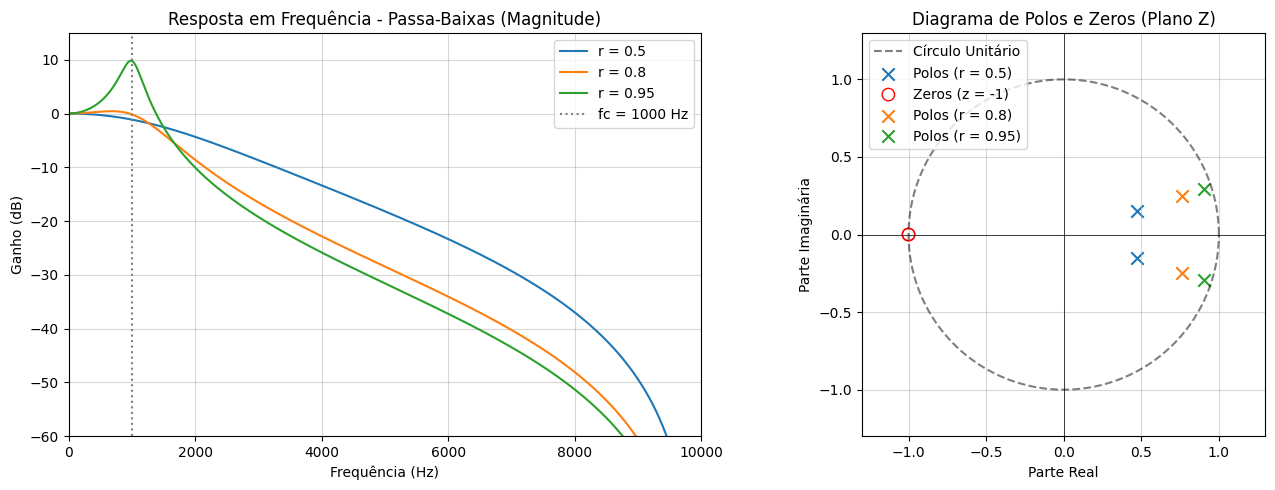

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import sympy as sp

# Parâmetros do projeto: Passa-Baixas
fs = 20000  # Frequência de amostragem (Hz)
fc = 1000  # Frequência de corte / ressonância (Hz)
wc = 2 * np.pi * fc / fs  # Frequência digital normalizada (rad/amostra)

# Variável simbólica z para impressão da equação
z = sp.Symbol('z')

# Valores de r para investigação
valores_r = [0.5, 0.8, 0.95]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Círculo unitário para o diagrama de polos e zeros
theta = np.linspace(0, 2 * np.pi, 300)
ax2.plot(
    np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Círculo Unitário'
)

for r in valores_r:
  # Coeficientes do denominador de 2ª ordem
  m1 = -2 * r * np.cos(wc)
  m2 = r**2

  # Ganho de normalização K para ganho unitário (0 dB) em DC (z = 1)
  K = (1 + m1 + m2) / 4

  # Numerador (dois zeros em z = -1) e Denominador
  num = K * np.array([1, 2, 1])
  den = np.array([1, m1, m2])

  # Montagem e impressão da equação H(z) com potências positivas de z
  num_sym = round(num[0], 4) * z**2 + round(num[1], 4) * z + round(num[2], 4)
  den_sym = z**2 + round(den[1], 4) * z + round(den[2], 4)
  H = num_sym / den_sym

  print(f'\n--- Função de Transferência H(z) para r = {r} ---')
  sp.pprint(H)

  # Resposta em Frequência
  w, h = signal.freqz(num, den, worN=2048, fs=fs)
  ax1.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f'r = {r}')

  # Polos e Zeros
  zeros, polos, _ = signal.tf2zpk(num, den)
  ax2.scatter(
      np.real(polos),
      np.imag(polos),
      marker='x',
      s=80,
      label=f'Polos (r = {r})',
  )
  if r == 0.5:
    ax2.scatter(
        np.real(zeros),
        np.imag(zeros),
        marker='o',
        facecolors='none',
        edgecolors='red',
        s=80,
        label='Zeros (z = -1)',
    )

# Formatação do gráfico de Magnitude
ax1.set_title('Resposta em Frequência - Passa-Baixas (Magnitude)')
ax1.set_xlabel('Frequência (Hz)')
ax1.set_ylabel('Ganho (dB)')
ax1.axvline(fc, color='gray', linestyle=':', label='fc = 1000 Hz')
ax1.set_xlim(0, fs / 2)
ax1.set_ylim(-60, 15)
ax1.grid(True, which='both', alpha=0.5)
ax1.legend()

# Formatação do Diagrama de Polos e Zeros
ax2.set_title('Diagrama de Polos e Zeros (Plano Z)')
ax2.set_xlabel('Parte Real')
ax2.set_ylabel('Parte Imaginária')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.axvline(0, color='black', linewidth=0.5)
ax2.set_aspect('equal')
ax2.set_xlim(-1.3, 1.3)
ax2.set_ylim(-1.3, 1.3)
ax2.grid(True, alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


Questão 1 - Letra b)


--- Função de Transferência H(z) para r = 0.5 ---
        2                    
0.5148⋅z  - 1.0295⋅z + 0.5148
─────────────────────────────
      2                      
     z  - 0.809⋅z + 0.25     

--- Função de Transferência H(z) para r = 0.8 ---
        2                    
0.7336⋅z  - 1.4672⋅z + 0.7336
─────────────────────────────
     2                       
    z  - 1.2944⋅z + 0.64     

--- Função de Transferência H(z) para r = 0.95 ---
        2                    
0.8599⋅z  - 1.7198⋅z + 0.8599
─────────────────────────────
    2                        
   z  - 1.5371⋅z + 0.9025    


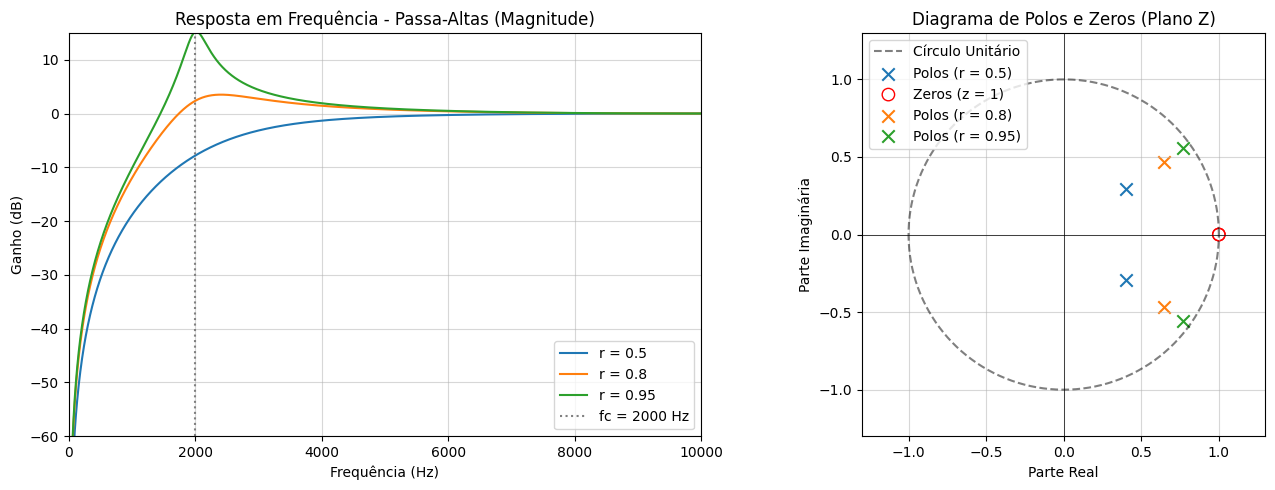

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import sympy as sp

# Parâmetros do projeto: Passa-Altas
fs = 20000  # Frequência de amostragem (Hz)
fc = 2000  # Frequência de corte / ressonância (Hz)
wc = 2 * np.pi * fc / fs  # Frequência digital normalizada (rad/amostra)

# Variável simbólica z para impressão da equação
z = sp.Symbol('z')

# Valores de r para investigação
valores_r = [0.5, 0.8, 0.95]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Círculo unitário para o diagrama de polos e zeros
theta = np.linspace(0, 2 * np.pi, 300)
ax2.plot(
    np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Círculo Unitário'
)

for r in valores_r:
  # Coeficientes do denominador de 2ª ordem
  m1 = -2 * r * np.cos(wc)
  m2 = r**2

  # Ganho de normalização K para ganho unitário (0 dB) em Nyquist (z = -1)
  K = (1 - m1 + m2) / 4

  # Numerador (dois zeros em z = 1) e Denominador
  num = K * np.array([1, -2, 1])
  den = np.array([1, m1, m2])

  # Montagem e impressão da equação H(z) com potências positivas de z
  # Corrigido: acessando cada índice individual do vetor 'num'
  num_sym = round(num[0], 4) * z**2 + round(num[1], 4) * z + round(num[2], 4)
  den_sym = z**2 + round(den[1], 4) * z + round(den[2], 4)
  H = num_sym / den_sym

  print(f'\n--- Função de Transferência H(z) para r = {r} ---')
  sp.pprint(H)

  # Resposta em Frequência
  w, h = signal.freqz(num, den, worN=2048, fs=fs)
  ax1.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f'r = {r}')

  # Polos e Zeros
  zeros, polos, _ = signal.tf2zpk(num, den)
  ax2.scatter(
      np.real(polos),
      np.imag(polos),
      marker='x',
      s=80,
      label=f'Polos (r = {r})',
  )
  if r == 0.5:
    ax2.scatter(
        np.real(zeros),
        np.imag(zeros),
        marker='o',
        facecolors='none',
        edgecolors='red',
        s=80,
        label='Zeros (z = 1)',
    )

# Formatação do gráfico de Magnitude
ax1.set_title('Resposta em Frequência - Passa-Altas (Magnitude)')
ax1.set_xlabel('Frequência (Hz)')
ax1.set_ylabel('Ganho (dB)')
ax1.axvline(fc, color='gray', linestyle=':', label='fc = 2000 Hz')
ax1.set_xlim(0, fs / 2)
ax1.set_ylim(-60, 15)
ax1.grid(True, which='both', alpha=0.5)
ax1.legend()

# Formatação do Diagrama de Polos e Zeros
ax2.set_title('Diagrama de Polos e Zeros (Plano Z)')
ax2.set_xlabel('Parte Real')
ax2.set_ylabel('Parte Imaginária')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.axvline(0, color='black', linewidth=0.5)
ax2.set_aspect('equal')
ax2.set_xlim(-1.3, 1.3)
ax2.set_ylim(-1.3, 1.3)
ax2.grid(True, alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

Questão 1 - Letra c)


--- Função de Transferência H(z) para r = 0.5 ---
         2          
 0.3858⋅z  - 0.3858 
────────────────────
 2                  
z  + 0.5878⋅z + 0.25

--- Função de Transferência H(z) para r = 0.8 ---
         2          
 0.1806⋅z  - 0.1806 
────────────────────
 2                  
z  + 0.9405⋅z + 0.64

--- Função de Transferência H(z) para r = 0.95 ---
          2           
  0.0488⋅z  - 0.0488  
──────────────────────
 2                    
z  + 1.1168⋅z + 0.9025


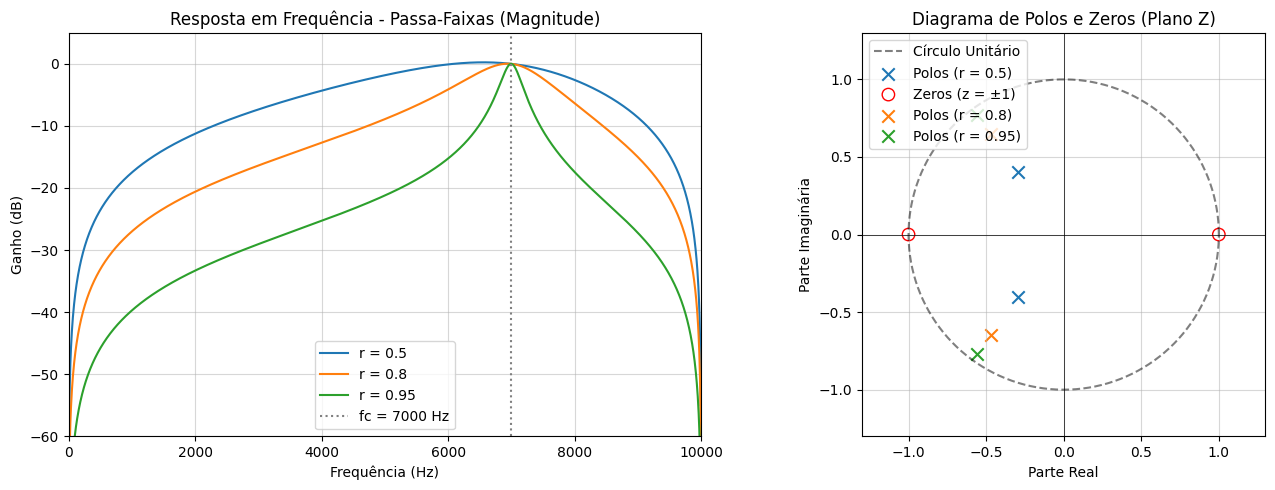

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import sympy as sp

# Parâmetros do projeto: Passa-Faixas
fs = 20000  # Frequência de amostragem (Hz)
fc = 7000  # Frequência central / ressonância (Hz)
wc = 2 * np.pi * fc / fs  # Frequência digital normalizada (rad/amostra)

# Variável simbólica z para impressão da equação
z = sp.Symbol('z')

# Valores de r para investigação
valores_r = [0.5, 0.8, 0.95]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Círculo unitário para o diagrama de polos e zeros
theta = np.linspace(0, 2 * np.pi, 300)
ax2.plot(
    np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Círculo Unitário'
)

for r in valores_r:
  # Coeficientes do denominador de 2ª ordem
  m1 = -2 * r * np.cos(wc)
  m2 = r**2

  # Ganho de normalização K para ganho unitário (0 dB) exato em z = e^(j*wc)
  z_wc = np.exp(1j * wc)
  ganho_sem_k = np.abs(
      (1 - z_wc**-2) / (1 + m1 * z_wc**-1 + m2 * z_wc**-2)
  )
  K = 1.0 / ganho_sem_k

  # Numerador (zeros em z = 1 e z = -1) e Denominador
  num = K * np.array([1, 0, -1])
  den = np.array([1, m1, m2])

  # Montagem e impressão da equação H(z) com potências positivas de z
  num_sym = round(num[0], 4) * z**2 + round(num[1], 4) * z + round(num[2], 4)
  den_sym = z**2 + round(den[1], 4) * z + round(den[2], 4)
  H = num_sym / den_sym

  print(f'\n--- Função de Transferência H(z) para r = {r} ---')
  sp.pprint(H)

  # Resposta em Frequência
  w, h = signal.freqz(num, den, worN=2048, fs=fs)
  ax1.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f'r = {r}')

  # Polos e Zeros
  zeros, polos, _ = signal.tf2zpk(num, den)
  ax2.scatter(
      np.real(polos),
      np.imag(polos),
      marker='x',
      s=80,
      label=f'Polos (r = {r})',
  )
  if r == 0.5:
    ax2.scatter(
        np.real(zeros),
        np.imag(zeros),
        marker='o',
        facecolors='none',
        edgecolors='red',
        s=80,
        label='Zeros (z = ±1)',
    )

# Formatação do gráfico de Magnitude
ax1.set_title('Resposta em Frequência - Passa-Faixas (Magnitude)')
ax1.set_xlabel('Frequência (Hz)')
ax1.set_ylabel('Ganho (dB)')
ax1.axvline(fc, color='gray', linestyle=':', label='fc = 7000 Hz')
ax1.set_xlim(0, fs / 2)
ax1.set_ylim(-60, 5)
ax1.grid(True, which='both', alpha=0.5)
ax1.legend()

# Formatação do Diagrama de Polos e Zeros
ax2.set_title('Diagrama de Polos e Zeros (Plano Z)')
ax2.set_xlabel('Parte Real')
ax2.set_ylabel('Parte Imaginária')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.axvline(0, color='black', linewidth=0.5)
ax2.set_aspect('equal')
ax2.set_xlim(-1.3, 1.3)
ax2.set_ylim(-1.3, 1.3)
ax2.grid(True, alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


Questão 1 - Letra d)


--- Função de Transferência H(z) para r = 0.5 ---
        2                    
0.8032⋅z  - 0.9443⋅z + 0.8032
─────────────────────────────
     2                       
    z  - 0.5878⋅z + 0.25     

--- Função de Transferência H(z) para r = 0.8 ---
        2                    
0.8485⋅z  - 0.9975⋅z + 0.8485
─────────────────────────────
     2                       
    z  - 0.9405⋅z + 0.64     

--- Função de Transferência H(z) para r = 0.95 ---
       2                   
0.953⋅z  - 1.1204⋅z + 0.953
───────────────────────────
   2                       
  z  - 1.1168⋅z + 0.9025   


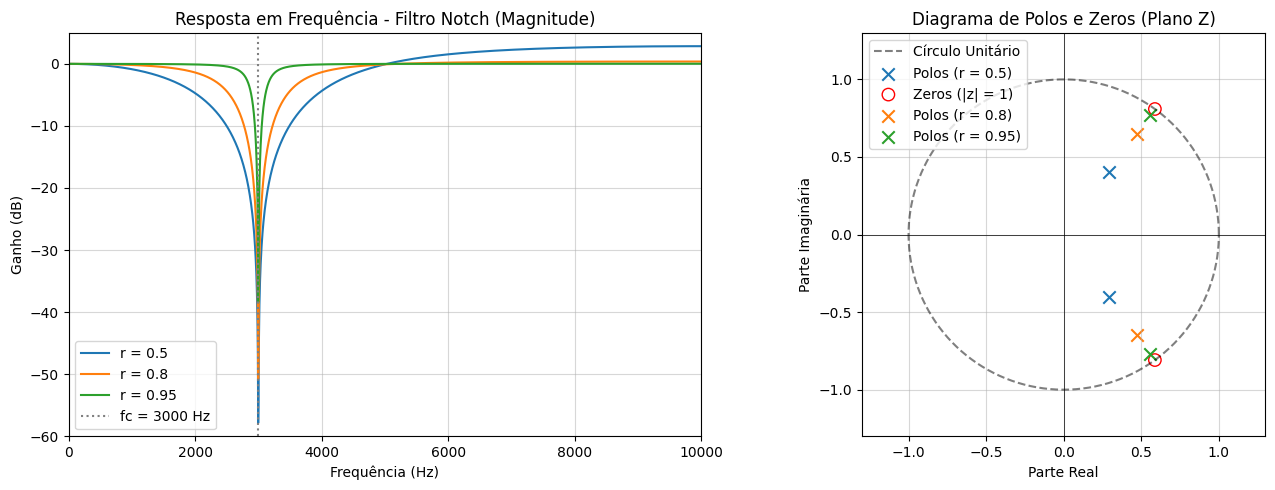

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import sympy as sp

# Parâmetros do projeto: Filtro Notch (Rejeita-Faixa)
fs = 20000
fc = 3000
wc = 2 * np.pi * fc / fs

# Variável simbólica z
z = sp.Symbol('z')

valores_r = [0.5, 0.8, 0.95]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

theta = np.linspace(0, 2 * np.pi, 300)
ax2.plot(
    np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Círculo Unitário'
)

for r in valores_r:
  b1 = -2 * np.cos(wc)
  m1 = -2 * r * np.cos(wc)
  m2 = r**2
  K = (1 + m1 + m2) / (2 + b1)

  num = K * np.array([1, b1, 1])
  den = np.array([1, m1, m2])

  # Impressão com z positivo (z^2, z^1, z^0)
  num_sym = round(num[0], 4) * z**2 + round(num[1], 4) * z + round(num[2], 4)
  den_sym = z**2 + round(den[1], 4) * z + round(den[2], 4)
  H = num_sym / den_sym

  print(f'\n--- Função de Transferência H(z) para r = {r} ---')
  sp.pprint(H)

  # Resposta em Frequência
  w, h = signal.freqz(num, den, worN=2048, fs=fs)
  ax1.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f'r = {r}')

  # Polos e Zeros
  zeros, polos, _ = signal.tf2zpk(num, den)
  ax2.scatter(
      np.real(polos),
      np.imag(polos),
      marker='x',
      s=80,
      label=f'Polos (r = {r})',
  )
  if r == 0.5:
    ax2.scatter(
        np.real(zeros),
        np.imag(zeros),
        marker='o',
        facecolors='none',
        edgecolors='red',
        s=80,
        label='Zeros (|z| = 1)',
    )

ax1.set_title('Resposta em Frequência - Filtro Notch (Magnitude)')
ax1.set_xlabel('Frequência (Hz)')
ax1.set_ylabel('Ganho (dB)')
ax1.axvline(fc, color='gray', linestyle=':', label='fc = 3000 Hz')
ax1.set_xlim(0, fs / 2)
ax1.set_ylim(-60, 5)
ax1.grid(True, which='both', alpha=0.5)
ax1.legend()

ax2.set_title('Diagrama de Polos e Zeros (Plano Z)')
ax2.set_xlabel('Parte Real')
ax2.set_ylabel('Parte Imaginária')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.axvline(0, color='black', linewidth=0.5)
ax2.set_aspect('equal')
ax2.set_xlim(-1.3, 1.3)
ax2.set_ylim(-1.3, 1.3)
ax2.grid(True, alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


Questão 2

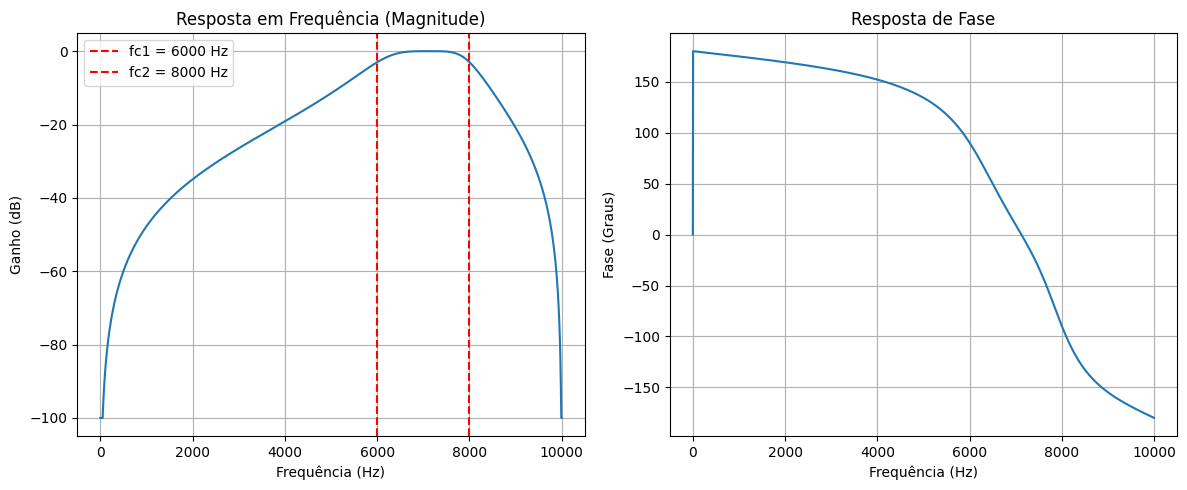

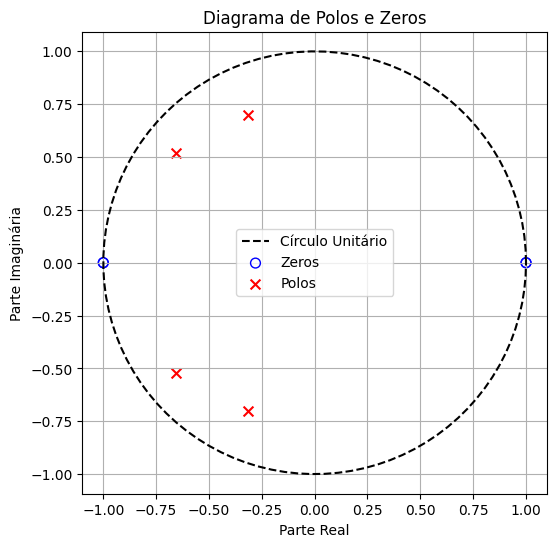

'\n\nComentários sobre os resultados:\n\n1. Resposta em Frequência:\n   O filtro projetado apresenta uma banda de passagem plana e bem definida entre fc1 = 6000 Hz e\n   fc2 = 8000 Hz (largura de banda de 2000 Hz centrada em 7000 Hz), com atenuação de -3 dB exatos\n   nas duas frequências de corte e decaimento acentuado nas bandas de rejeição.\n\n2. Diagrama de Polos e Zeros:\n   - Como utilizamos 2 blocos básicos de 2ª ordem em cascata (ordem 4 no total), o sistema possui\n     4 zeros (dois em z = 1 e dois em z = -1) e 2 pares de polos complexos conjugados localizados\n     estritamente dentro do círculo unitário, garantindo a estabilidade do filtro.\n   - Os dois pares de polos distribuem-se ao redor dos ângulos correspondentes a 6000 Hz e 8000 Hz,\n     sustentando o ganho plano em toda a faixa de passagem.\n\n3. Comparação com a Questão 1 (Letra c):\n   - Centro de frequência: Ambos os filtros estão centrados em 7000 Hz (média entre 6000 Hz e 8000 Hz).\n   - Seletividade e Banda P

In [23]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

# Parâmetros do filtro
fs = 20000.0  # Frequência de amostragem (Hz)
fc1 = 6000.0  # Frequência de corte inferior (Hz)
fc2 = 8000.0  # Frequência de corte superior (Hz)
nyq = 0.5 * fs

# Normalização das frequências de corte
low = fc1 / nyq
high = fc2 / nyq

# Ajuste: order = 2 em passa-faixas resulta em 4ª ordem total (cascata de 2 blocos de 2ª ordem)
order = 2
sos = signal.butter(order, [low, high], btype='band', output='sos')

# 1. Resposta em Frequência
w, h = signal.sosfreqz(sos, worN=2000, fs=fs)

plt.figure(figsize=(12, 5))

# Gráfico da Magnitude
plt.subplot(1, 2, 1)
plt.plot(w, 20 * np.log10(np.maximum(abs(h), 1e-5)))
plt.title('Resposta em Frequência (Magnitude)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Ganho (dB)')
plt.grid(True)
plt.axvline(fc1, color='red', linestyle='--', label='fc1 = 6000 Hz')
plt.axvline(fc2, color='red', linestyle='--', label='fc2 = 8000 Hz')
plt.legend()

# Gráfico da Fase
plt.subplot(1, 2, 2)
plt.plot(w, np.angle(h) * 180 / np.pi)
plt.title('Resposta de Fase')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Fase (Graus)')
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Diagramas de Polos e Zeros
# Extração de polos e zeros a partir de SOS
z, p, k = signal.sos2zpk(sos)

plt.figure(figsize=(6, 6))
# Círculo unitário
theta = np.linspace(0, 2 * np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo Unitário')

# Plot de polos (x) e zeros (o)
plt.scatter(
    np.real(z),
    np.imag(z),
    s=50,
    marker='o',
    facecolors='none',
    edgecolors='b',
    label='Zeros',
)
plt.scatter(np.real(p), np.imag(p), s=50, marker='x', color='r', label='Polos')

plt.title('Diagrama de Polos e Zeros')
plt.xlabel('Parte Real')
plt.ylabel('Parte Imaginária')
plt.grid(True)
plt.axis('equal')
plt.legend()
plt.show()

# --- COMENTÁRIOS E COMPARAÇÃO ---
"""

Comentários sobre os resultados:

1. Resposta em Frequência:
   O filtro projetado apresenta uma banda de passagem plana e bem definida entre fc1 = 6000 Hz e
   fc2 = 8000 Hz (largura de banda de 2000 Hz centrada em 7000 Hz), com atenuação de -3 dB exatos
   nas duas frequências de corte e decaimento acentuado nas bandas de rejeição.

2. Diagrama de Polos e Zeros:
   - Como utilizamos 2 blocos básicos de 2ª ordem em cascata (ordem 4 no total), o sistema possui
     4 zeros (dois em z = 1 e dois em z = -1) e 2 pares de polos complexos conjugados localizados
     estritamente dentro do círculo unitário, garantindo a estabilidade do filtro.
   - Os dois pares de polos distribuem-se ao redor dos ângulos correspondentes a 6000 Hz e 8000 Hz,
     sustentando o ganho plano em toda a faixa de passagem.

3. Comparação com a Questão 1 (Letra c):
   - Centro de frequência: Ambos os filtros estão centrados em 7000 Hz (média entre 6000 Hz e 8000 Hz).
   - Seletividade e Banda Passante: Na Questão 1(c), o passa-faixas usava apenas um único bloco de
     2ª ordem (1 par de polos), gerando apenas um pico pontual em 7000 Hz, onde a largura de banda
     dependia do raio r (por exemplo, BW ≈ 3183 Hz para r = 0,5 e BW ≈ 318 Hz para r = 0,95). Nesta
     questão, a cascata de dois blocos de 2ª ordem permite controlar diretamente fc1 e fc2, criando
     uma banda passante plana de 2000 Hz com transições muito mais abruptas (maior seletividade).

"""


Questão 3


--- Função de Transferência Resultante H(z) (r = 0.75) ---
        4           3           2                   
0.5405⋅z  - 1.6834⋅z  + 2.2582⋅z  - 1.2699⋅z + 0.304
────────────────────────────────────────────────────
      4           3           2                     
 1.0⋅z  - 1.8901⋅z  + 1.7863⋅z  - 1.0632⋅z + 0.3164 


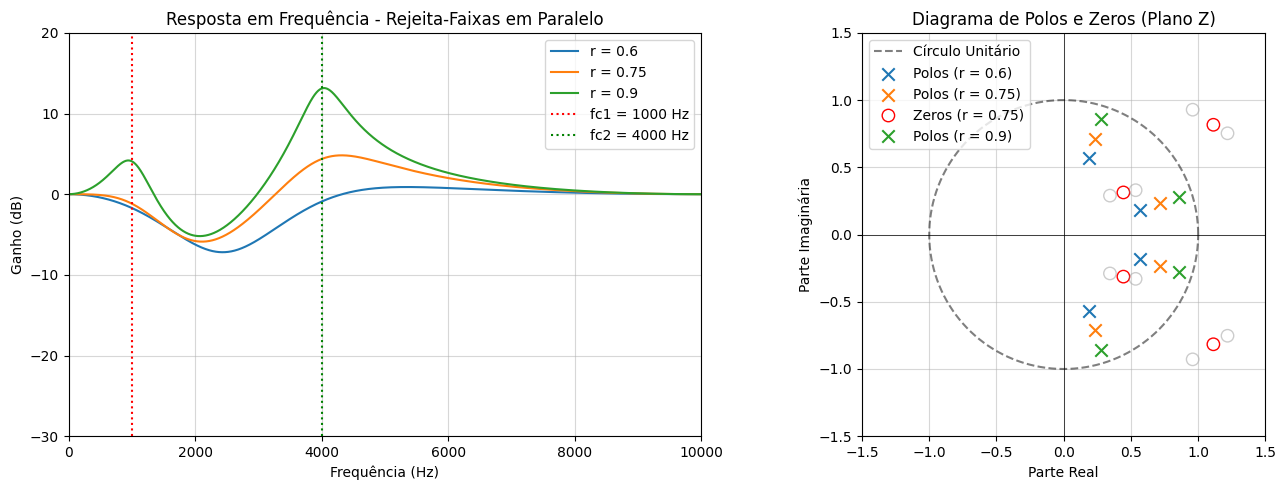

In [25]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import sympy as sp

# Parâmetros do projeto: Rejeita-Faixas em Paralelo
fs = 20000.0  # Frequência de amostragem (Hz)
fc1 = 1000.0  # Frequência de corte inferior - Passa-Baixas (Hz)
fc2 = 4000.0  # Frequência de corte superior - Passa-Altas (Hz)

wc1 = 2 * np.pi * fc1 / fs
wc2 = 2 * np.pi * fc2 / fs

z = sp.Symbol('z')
valores_r = [0.6, 0.75, 0.9]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Círculo unitário
theta = np.linspace(0, 2 * np.pi, 300)
ax2.plot(
    np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Círculo Unitário'
)

for r in valores_r:
  # Bloco 1: Passa-Baixas de 2ª ordem (fc1 = 1000 Hz)
  m1_pb = -2 * r * np.cos(wc1)
  m2_pb = r**2
  K_pb = (1 + m1_pb + m2_pb) / 4
  num_pb = K_pb * np.array([1, 2, 1])
  den_pb = np.array([1, m1_pb, m2_pb])

  # Bloco 2: Passa-Altas de 2ª ordem (fc2 = 4000 Hz)
  m1_pa = -2 * r * np.cos(wc2)
  m2_pa = r**2
  K_pa = (1 - m1_pa + m2_pa) / 4
  num_pa = K_pa * np.array([1, -2, 1])
  den_pa = np.array([1, m1_pa, m2_pa])

  # Associação em Paralelo: H(z) = H_pb(z) + H_pa(z)
  num_total = np.convolve(num_pb, den_pa) + np.convolve(num_pa, den_pb)
  den_total = np.convolve(den_pb, den_pa)

  if r == 0.75:
    num_sym = sum(
        round(num_total[i], 4) * z ** (4 - i) for i in range(len(num_total))
    )
    den_sym = sum(
        round(den_total[i], 4) * z ** (4 - i) for i in range(len(den_total))
    )
    print(f'\n--- Função de Transferência Resultante H(z) (r = {r}) ---')
    sp.pprint(num_sym / den_sym)

  # 1. Resposta em Frequência
  w, h = signal.freqz(num_total, den_total, worN=2048, fs=fs)
  ax1.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f'r = {r}')

  # 2. Diagrama de Polos e Zeros
  zeros, polos, _ = signal.tf2zpk(num_total, den_total)
  ax2.scatter(
      np.real(polos),
      np.imag(polos),
      marker='x',
      s=80,
      label=f'Polos (r = {r})',
  )
  ax2.scatter(
      np.real(zeros),
      np.imag(zeros),
      marker='o',
      facecolors='none',
      edgecolors='red' if r == 0.75 else 'gray',
      alpha=1.0 if r == 0.75 else 0.4,
      s=80,
      label='Zeros (r = 0.75)' if r == 0.75 else '',
  )

# Formatação do gráfico de Magnitude (limite superior ampliado para 20 dB)
ax1.set_title('Resposta em Frequência - Rejeita-Faixas em Paralelo')
ax1.set_xlabel('Frequência (Hz)')
ax1.set_ylabel('Ganho (dB)')
ax1.axvline(fc1, color='red', linestyle=':', label='fc1 = 1000 Hz')
ax1.axvline(fc2, color='green', linestyle=':', label='fc2 = 4000 Hz')
ax1.set_xlim(0, fs / 2)
ax1.set_ylim(-30, 20)
ax1.grid(True, which='both', alpha=0.5)
ax1.legend()

# Formatação do Diagrama de Polos e Zeros (margem ampliada para 1.5)
ax2.set_title('Diagrama de Polos e Zeros (Plano Z)')
ax2.set_xlabel('Parte Real')
ax2.set_ylabel('Parte Imaginária')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.axvline(0, color='black', linewidth=0.5)
ax2.set_aspect('equal')
ax2.set_xlim(-1.5, 1.5)
ax2.set_ylim(-1.5, 1.5)
ax2.grid(True, alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


Síntese comparativa. Enquanto o filtro Notch é ideal para eliminar uma única frequência interferente (como um ruído senoidal de rede) sem alterar o restante do espectro, o rejeita-faixas em paralelo permite suprimir toda uma região espectral extensa 1000 Hz a 4000 Hz, ao custo de maior ordem computacional e de uma atenuação finita na banda rejeitada (já que os zeros não repousam exatamente sobre o círculo unitário).

Questão 4

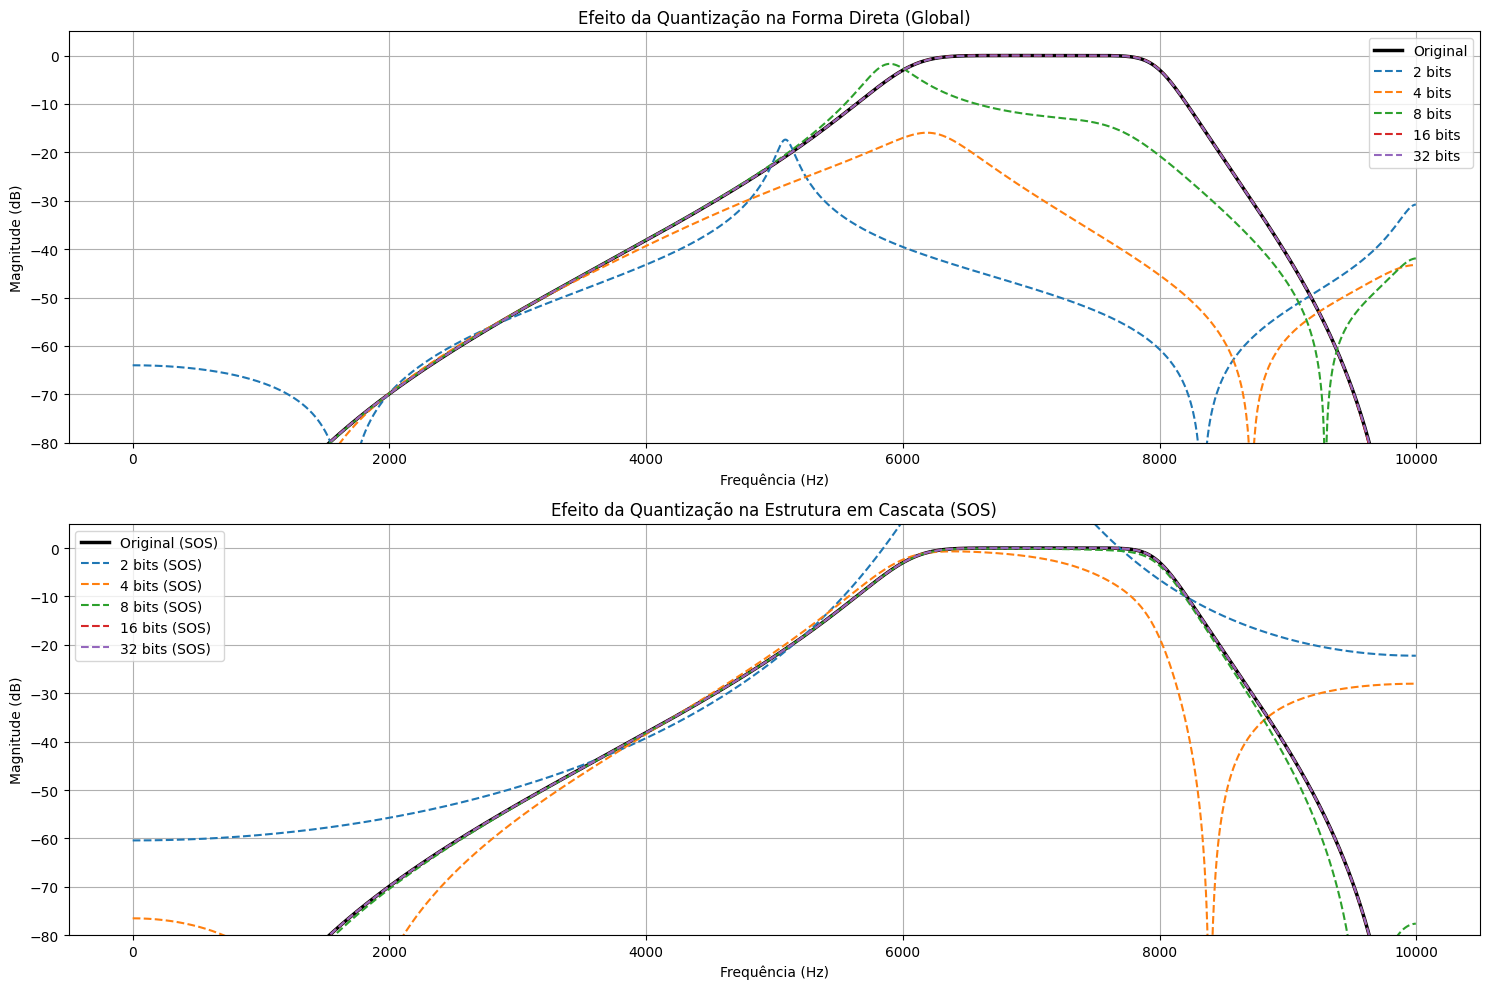

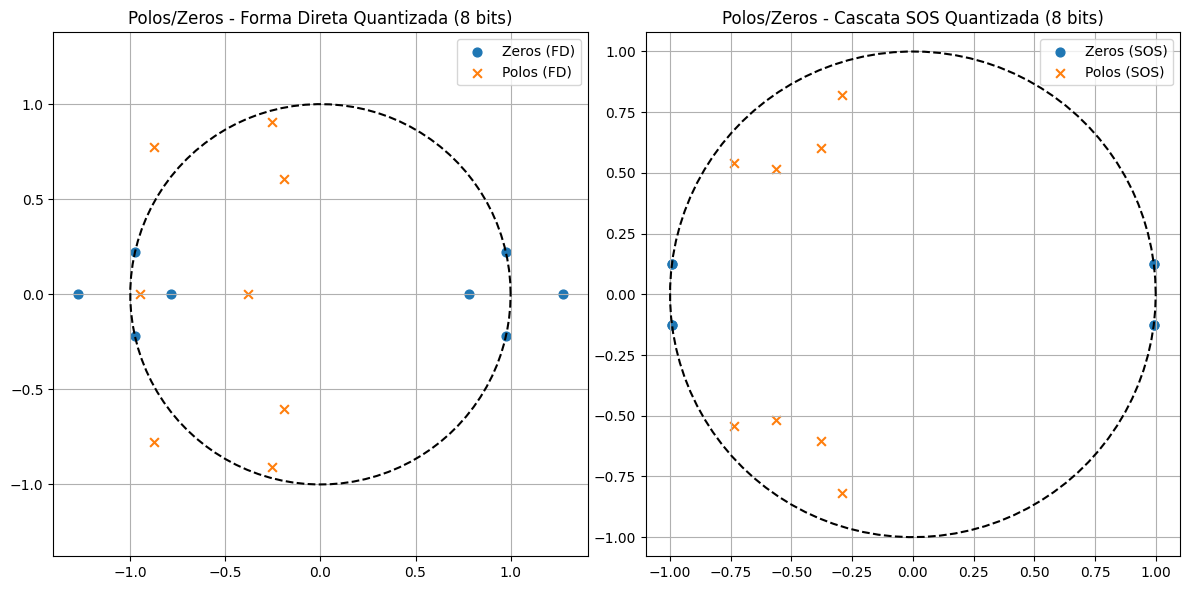

'\nComentários sobre os resultados da quantização:\n\n1. Sensibilidade ao Comprimento da Palavra (bits):\n   - Com 32 e 16 bits, ambas as estruturas se comportam de maneira ideal e estável.\n   - Com 8 bits, notamos pequenas distorções na banda de passagem, contudo, a estrutura em cascata SOS\n     mantém o formato original do filtro de maneira visivelmente superior à Forma Direta global.\n   - Com 4 e 2 bits, as características passa-faixas são completamente degradadas em ambas as implementações,\n     indicando que o mínimo de bits de precisão aceitável para o projeto deste filtro em ponto fixo é de cerca de 8 bits.\n\n2. Estabilidade e Diagrama de Polos e Zeros:\n   - Na Forma Direta com 8 bits, pequenos desvios nos coeficientes deslocam de maneira desproporcional os polos.\n     Isso ocorre devido ao fato de que, em ordens maiores, as raízes do polinômio do denominador (polos)\n     são altamente sensíveis às variações dos seus coeficientes (fenômeno conhecido como Sensibilidade de

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Parâmetros originais do filtro (Questão 2)
fs = 20000.0
fc1 = 6000.0
fc2 = 8000.0
nyq = 0.5 * fs
low = fc1 / nyq
high = fc2 / nyq
order = 4

# Filtro original em representação SOS e Forma Direta (b, a)
sos_orig = signal.butter(order, [low, high], btype='band', output='sos')
b_orig, a_orig = signal.butter(order, [low, high], btype='band', output='ba')

# Função de quantização uniforme de ponto fixo
def quantize_coefficients(coefs, bits):
    if bits >= 32:
        return coefs.copy()

    max_val = np.max(np.abs(coefs))
    if max_val == 0:
        return coefs

    # Normaliza os coeficientes na faixa [-1, 1]
    norm_coefs = coefs / max_val

    # Quantiza na faixa discreta para os bits fornecidos
    levels = 2**(bits - 1) - 1
    quant_coefs = np.round(norm_coefs * levels) / levels

    # Retorna à escala original
    return quant_coefs * max_val

bits_list = [2, 4, 8, 16, 32]

# 1. Resposta em frequência para quantização na Forma Direta
plt.figure(figsize=(15, 10))

plt.subplot(2, 1, 1)
# Resposta original
w, h_orig = signal.freqz(b_orig, a_orig, worN=2000, fs=fs)
plt.plot(w, 20 * np.log10(np.maximum(abs(h_orig), 1e-5)), 'k-', linewidth=2.5, label='Original')

for b_val in bits_list:
    # Na Forma Direta, o termo a_orig[0] é sempre 1.0. Vamos preservá-lo e quantizar o resto.
    b_q = quantize_coefficients(b_orig, b_val)
    a_q = a_orig.copy()
    a_q[1:] = quantize_coefficients(a_orig[1:], b_val)

    w, h_q = signal.freqz(b_q, a_q, worN=2000, fs=fs)
    plt.plot(w, 20 * np.log10(np.maximum(abs(h_q), 1e-5)), '--', label=f'{b_val} bits')

plt.title('Efeito da Quantização na Forma Direta (Global)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude (dB)')
plt.ylim([-80, 5])
plt.grid(True)
plt.legend()

# 2. Resposta em frequência para quantização em Cascata (SOS)
plt.subplot(2, 1, 2)
w, h_sos_orig = signal.sosfreqz(sos_orig, worN=2000, fs=fs)
plt.plot(w, 20 * np.log10(np.maximum(abs(h_sos_orig), 1e-5)), 'k-', linewidth=2.5, label='Original (SOS)')

for b_val in bits_list:
    sos_q = sos_orig.copy()
    for i in range(sos_q.shape[0]):
        # Quantiza separadamente o numerador (b0, b1, b2)
        sos_q[i, 0:3] = quantize_coefficients(sos_q[i, 0:3], b_val)
        # No denominador, o termo a0 (sos_q[i, 3]) deve ser sempre exatamente 1.0
        sos_q[i, 3] = 1.0
        # Quantizamos apenas os coeficientes de realimentação (a1, a2)
        sos_q[i, 4:6] = quantize_coefficients(sos_q[i, 4:6], b_val)

    w, h_sos_q = signal.sosfreqz(sos_q, worN=2000, fs=fs)
    plt.plot(w, 20 * np.log10(np.maximum(abs(h_sos_q), 1e-5)), '--', label=f'{b_val} bits (SOS)')

plt.title('Efeito da Quantização na Estrutura em Cascata (SOS)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude (dB)')
plt.ylim([-80, 5])
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# --- DIAGRAMA DE POLOS E ZEROS DOS SISTEMAS QUANTIZADOS (Comparativo 8 bits) ---
plt.figure(figsize=(12, 6))

# Polos/Zeros Forma Direta com 8 bits
b_q8 = quantize_coefficients(b_orig, 8)
a_q8 = a_orig.copy()
a_q8[1:] = quantize_coefficients(a_orig[1:], 8)
z_fd, p_fd, _ = signal.tf2zpk(b_q8, a_q8)

# Polos/Zeros SOS com 8 bits
sos_q8 = sos_orig.copy()
for i in range(sos_q8.shape[0]):
    sos_q8[i, 0:3] = quantize_coefficients(sos_q8[i, 0:3], 8)
    sos_q8[i, 3] = 1.0
    sos_q8[i, 4:6] = quantize_coefficients(sos_q8[i, 4:6], 8)
z_sos, p_sos, _ = signal.sos2zpk(sos_q8)

theta = np.linspace(0, 2*np.pi, 100)

# Subplot Forma Direta
plt.subplot(1, 2, 1)
plt.plot(np.cos(theta), np.sin(theta), 'k--')
plt.scatter(np.real(z_fd), np.imag(z_fd), s=40, marker='o', label='Zeros (FD)')
plt.scatter(np.real(p_fd), np.imag(p_fd), s=40, marker='x', label='Polos (FD)')
plt.title('Polos/Zeros - Forma Direta Quantizada (8 bits)')
plt.axis('equal')
plt.grid(True)
plt.legend()

# Subplot SOS
plt.subplot(1, 2, 2)
plt.plot(np.cos(theta), np.sin(theta), 'k--')
plt.scatter(np.real(z_sos), np.imag(z_sos), s=40, marker='o', label='Zeros (SOS)')
plt.scatter(np.real(p_sos), np.imag(p_sos), s=40, marker='x', label='Polos (SOS)')
plt.title('Polos/Zeros - Cascata SOS Quantizada (8 bits)')
plt.axis('equal')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# --- COMENTÁRIOS ---
"""
Comentários sobre os resultados da quantização:

1. Sensibilidade ao Comprimento da Palavra (bits):
   - Com 32 e 16 bits, ambas as estruturas se comportam de maneira ideal e estável.
   - Com 8 bits, notamos pequenas distorções na banda de passagem, contudo, a estrutura em cascata SOS
     mantém o formato original do filtro de maneira visivelmente superior à Forma Direta global.
   - Com 4 e 2 bits, as características passa-faixas são completamente degradadas em ambas as implementações,
     indicando que o mínimo de bits de precisão aceitável para o projeto deste filtro em ponto fixo é de cerca de 8 bits.

2. Estabilidade e Diagrama de Polos e Zeros:
   - Na Forma Direta com 8 bits, pequenos desvios nos coeficientes deslocam de maneira desproporcional os polos.
     Isso ocorre devido ao fato de que, em ordens maiores, as raízes do polinômio do denominador (polos)
     são altamente sensíveis às variações dos seus coeficientes (fenômeno conhecido como Sensibilidade de Wilkinson).
   - Na estrutura SOS, ao decompor o sistema em seções de 2ª ordem, isolamos as raízes em polinômios de baixo grau,
     o que atenua significativamente essa sensibilidade. Os polos do SOS mantêm-se em posições praticamente idênticas
     às originais e em áreas seguras dentro do círculo unitário, assegurando a estabilidade.
"""

Questão 5

In [27]:
from google.colab import files
import io
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

print("Por favor, faça o upload do arquivo 'handel.wav':")
uploaded = files.upload()

if 'handel.wav' in uploaded:
    # Carrega o áudio de entrada x(t)
    fs_audio, x = wavfile.read(io.BytesIO(uploaded['handel.wav']))

    # Normaliza o sinal de áudio se necessário
    if x.dtype == np.int16:
        x = x / 32768.0
    elif x.dtype == np.int32:
        x = x / 2147483648.0

    N = len(x)
    t = np.arange(N) / fs_audio

    # Modelagem das interferências senoidais
    # 0.05 * cos(200 * pi * t) -> frequência de 100 Hz
    # 0.075 * sin(4000 * pi * t) -> frequência de 2000 Hz
    interf_low = 0.05 * np.cos(200 * np.pi * t)
    interf_high = 0.075 * np.sin(4000 * np.pi * t)

    variances = [1e-2, 1e-1, 1.0]
    y_signals = {}

    # Plot do sinal original e das versões ruidosas
    plt.figure(figsize=(15, 12))

    plt.subplot(4, 1, 1)
    plt.plot(t, x, 'k-', alpha=0.7, label='Original x(t)')
    plt.title('Sinal Original e Sinais Contaminados y(t)')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.legend()

    # Geração dos sinais corrompidos
    for i, var in enumerate(variances, start=2):
        std_dev = np.sqrt(var)
        noise = np.random.normal(0, std_dev, N)

        # y(t) = x(t) + 0.05*cos(200*pi*t) + 0.075*sin(4000*pi*t) + n(t)
        y = x + interf_low + interf_high + noise
        y_signals[var] = y

        plt.subplot(4, 1, i)
        plt.plot(t, y, alpha=0.7, label=f'Contaminado y(t) (σ² = {var})')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.legend()

    plt.xlabel('Tempo (s)')
    plt.tight_layout()
    plt.show()
    print("Sinais gerados e salvos no dicionário 'y_signals' com sucesso!")
else:
    print("Erro: Por favor, envie exatamente o arquivo com o nome 'handel.wav'.")

Por favor, faça o upload do arquivo 'handel.wav':


Erro: Por favor, envie exatamente o arquivo com o nome 'handel.wav'.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Cálculo da frequência correspondente para cada ponto da FFT unilateral
freqs = np.fft.rfftfreq(N, d=1/fs_audio)

plt.figure(figsize=(15, 12))

# 1. Espectro do Sinal Original x(t)
fft_x = np.fft.rfft(x)
plt.subplot(4, 1, 1)
plt.plot(freqs, 20 * np.log10(np.maximum(np.abs(fft_x), 1e-5)), 'k-', alpha=0.8, label='Original x(t)')
plt.title('Espectro de Magnitude (FFT) - Sinal Original vs. Sinais Contaminados')
plt.ylabel('Magnitude (dB)')
plt.grid(True)
plt.legend()

# 2. Espectro para cada nível de ruído em y(t)
for i, var in enumerate(variances, start=2):
    y_current = y_signals[var]
    fft_y = np.fft.rfft(y_current)

    plt.subplot(4, 1, i)
    plt.plot(freqs, 20 * np.log10(np.maximum(np.abs(fft_y), 1e-5)), label=f'Contaminado y(t) (σ² = {var})')

    # Destaque visual das componentes interferentes em 100 Hz e 2000 Hz
    plt.axvline(100, color='red', linestyle='--', alpha=0.7, label='Interferência 100 Hz')
    plt.axvline(2000, color='orange', linestyle='--', alpha=0.7, label='Interferência 2000 Hz')

    plt.ylabel('Magnitude (dB)')
    plt.grid(True)
    plt.legend()

plt.xlabel('Frequência (Hz)')
plt.tight_layout()
plt.show()

# --- COMENTÁRIOS E AVALIAÇÃO SUBJETIVA ---
print("""
Comentários sobre os Resultados Obtidos (Questão 5a):

1. Comparação no Domínio do Tempo:
   - Para σ² = 1e-2, o sinal de áudio original ainda é reconhecível visualmente no domínio do tempo,
     embora a interferência de alta frequência (2000 Hz) adicione uma oscilação perceptível sobre o sinal.
   - Para σ² = 1e-1 e 1.0, o ruído gaussiano domina completamente a forma de onda temporal,
     tornando impossível distinguir as características do áudio original a olho nu.

2. Comparação no Domínio da Frequência:
   - No espectro do sinal original, a energia está distribuída principalmente nas baixas e médias frequências.
   - Nos espectros dos sinais contaminados, as interferências de 100 Hz e 2000 Hz aparecem nitidamente como picos
     estreitos e proeminentes sobressaindo da assinatura espectral do áudio.
   - Conforme a variância do ruído branco aumenta (de 1e-2 para 1.0), o patamar de ruído de fundo (noise floor)
     sobe uniformemente em todas as frequências. Com σ² = 1.0, o ruído cobre quase todo o espectro do sinal útil,
     mas os picos senoidais ainda são visíveis devido ao seu caráter puramente tonal de banda estreita.

3. Avaliação Subjetiva do Áudio y(t):
   - Com σ² = 1e-2: Ouve-se a música de fundo ("Handel") com um zumbido grave contínuo de 100 Hz (semelhante ao 'hum' da rede elétrica)
     e um apito agudo em 2000 Hz, acompanhados por um chiado leve.
   - Com σ² = 1e-1: O chiado (ruído de fundo) fica muito forte, obscurecendo partes mais suaves da música,
     embora o tom de 2000 Hz e o zumbido ainda sejam claramente audíveis.
   - Com σ² = 1.0: O ruído estático torna-se ensurdecedor. A música é praticamente indetectável, sendo perceptível
     apenas o forte ruído branco de fundo e os dois tons espúrios (100 Hz e 2000 Hz) que se sobressaem do ruído.
""")